# Clustering Case Study: Customer Segmentation with K-Means -  Tier 3
***
This case study is based on [this blog post](http://blog.yhat.com/posts/customer-segmentation-using-python.html) by the `yhat` blog. Please feel free to refer to the post for additional information, and solutions.

Structure of the mini-project:

1. **Sourcing and loading**
    * Load the data
    * Explore the data


2. **Cleaning, transforming and visualizing**
    * Data Wrangling: Exercise Set 1
        - Creating a matrix with a binary indicator for whether they responded to a given offer
        - Ensure that in doing so, NAN values are dealt with appropriately
    

3. **Modelling** 
    * K-Means clustering: Exercise Sets 2 and 3
        - Choosing K: The Elbow method
        - Choosing K: The Silhouette method
        - Choosing K: The Gap statistic method
    
    * Visualizing clusters with PCA: Exercise Sets 4 and 5


4. **Conclusions and next steps**
    * Conclusions
    * Other clustering algorithms (Exercise Set 6)

In [1]:
%matplotlib inline
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

# Setup Seaborn
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=0.9)

## 1. Sourcing and loading
### 1a. Load the data
The dataset contains information on marketing newsletters/e-mail campaigns (e-mail offers sent to customers) and transaction level data from customers. The transactional data shows which offer customers responded to, and what the customer ended up buying. The data is presented as an Excel workbook containing two worksheets. Each worksheet contains a different dataset.

In [2]:
# Load the data

import os
import warnings
import pandas as pd

# Suppress the specific openpyxl warning
warnings.filterwarnings(
    "ignore",
    message="Unknown extension is not supported and will be removed",
    category=UserWarning,
    module="openpyxl"
)

# Set the file path
file_path = "WineKMC.xlsx"

# Check that the file exists
if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"Excel file not found in: {os.getcwd()}"
    )

# Load the Offer Information worksheet
df_offers = pd.read_excel(
    file_path,
    sheet_name="OfferInformation"
)

# Rename the offer columns
df_offers.columns = [
    "offer_id",
    "campaign",
    "varietal",
    "min_qty",
    "discount",
    "origin",
    "past_peak"
]

### 1b. Explore the data

In [3]:
# Display the first five rows of the offers dataset
display(df_offers.head())

# Check the offers dataset information
df_offers.info()

# Check for missing values
display(df_offers.isnull().sum())

,offer_id,campaign,varietal,min_qty,discount,origin,past_peak
0,1,January,Malbec,72,56,France,False
1,2,January,Pinot Noir,72,17,France,False
2,3,February,Espumante,144,32,Oregon,True
3,4,February,Champagne,72,48,France,True
4,5,February,Cabernet Sauvignon,144,44,New Zealand,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   offer_id   32 non-null     int64 
 1   campaign   32 non-null     object
 2   varietal   32 non-null     object
 3   min_qty    32 non-null     int64 
 4   discount   32 non-null     int64 
 5   origin     32 non-null     object
 6   past_peak  32 non-null     bool  
dtypes: bool(1), int64(3), object(3)
memory usage: 1.7+ KB


offer_id     0
campaign     0
varietal     0
min_qty      0
discount     0
origin       0
past_peak    0
dtype: int64

We see that the first dataset contains information about each offer such as the month it is in effect and several attributes about the wine that the offer refers to: the variety, minimum quantity, discount, country of origin and whether or not it is past peak. The second dataset in the second worksheet contains transactional data -- which offer each customer responded to.

In [4]:
df_transactions = pd.read_excel("./WineKMC.xlsx", sheet_name=1)
df_transactions.columns = ["customer_name", "offer_id"]
df_transactions['n'] = 1
df_transactions.head()

,customer_name,offer_id,n
0,Smith,2,1
1,Smith,24,1
2,Johnson,17,1
3,Johnson,24,1
4,Johnson,26,1


## 2. Cleaning, transforming and visualizing
### 2a. Data Wrangling

We're trying to learn more about how our customers behave, so we can use their behavior (whether or not they purchased something based on an offer) as a way to group similar minded customers together. We can then study those groups to look for patterns and trends which can help us formulate future offers.

The first thing we need is a way to compare customers. To do this, we're going to create a matrix that contains each customer and a 0/1 indicator for whether or not they responded to a given offer. 

<div class="span5 alert alert-info">
<h3>Checkup Exercise Set I</h3>

<p><b>Exercise:</b> Create a data frame where each row has the following columns (Use the pandas [`merge`](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.DataFrame.merge.html) and [`pivot_table`](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.pivot_table.html) functions for this purpose):
<ul>
<li> customer_name
<li> One column for each offer, with a 1 if the customer responded to the offer
</ul>
<p>Make sure you also deal with any weird values such as `NaN`. Read the documentation to develop your solution.</p>
</div>

In [5]:
# Merge transactions with offer information, then create a customer-by-offer matrix.
# The merge keeps only valid customer responses associated with known offers.
df = pd.merge(
    df_offers,
    df_transactions,
    on="offer_id",
    how="inner",
    validate="one_to_many"
)

# Pivot so each row is a customer and each offer is a separate 0/1 column.
# Fill NaN with 0 because a missing response means the customer did not accept that offer.
customer_offer_matrix = df.pivot_table(
    index="customer_name",
    columns="offer_id",
    values="n",
    aggfunc="max",
    fill_value=0
)

# Ensure the matrix contains binary indicators, not counts.
customer_offer_matrix = (customer_offer_matrix > 0).astype(int)

# Keep customer names as a regular column for later merging and plotting.
customer_offer_matrix = customer_offer_matrix.reset_index()
customer_offer_matrix.columns.name = None

# Display the resulting customer-by-offer matrix and check its dimensions.
display(customer_offer_matrix.head())
print("Customer-offer matrix shape:", customer_offer_matrix.shape)
print("Missing values:", customer_offer_matrix.isna().sum().sum())
print("Number of customers:", customer_offer_matrix["customer_name"].nunique())
print("Number of offers:", customer_offer_matrix.shape[1] - 1)

,customer_name,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,32
0,Adams,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
1,Allen,0,0,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
2,Anderson,0,0,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
3,Bailey,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,Baker,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0


Customer-offer matrix shape: (100, 33)
Missing values: 0
Number of customers: 100
Number of offers: 32


## 3. Modelling 
### 3a. K-Means Clustering

Recall that in K-Means Clustering we want to *maximize* the distance between centroids and *minimize* the distance between data points and the respective centroid for the cluster they are in. True evaluation for unsupervised learning would require labeled data; however, we can use a variety of intuitive metrics to try to pick the number of clusters K. We will introduce two methods: the Elbow method, the Silhouette method and the gap statistic.

#### 3ai. Choosing K: The Elbow Sum-of-Squares Method

The first method looks at the sum-of-squares error in each cluster against $K$. We compute the distance from each data point to the center of the cluster (centroid) to which the data point was assigned. 

$$SS = \sum_k \sum_{x_i \in C_k} \sum_{x_j \in C_k} \left( x_i - x_j \right)^2 = \sum_k \sum_{x_i \in C_k} \left( x_i - \mu_k \right)^2$$

where $x_i$ is a point, $C_k$ represents cluster $k$ and $\mu_k$ is the centroid for cluster $k$. We can plot SS vs. $K$ and choose the *elbow point* in the plot as the best value for $K$. The elbow point is the point at which the plot starts descending much more slowly. 

**Hint:** the Elbow Method is discussed in part 2 of the Harvard Clustering lecture. 

<div class="span5 alert alert-info">
<h3>Checkup Exercise Set II</h3>

<p><b>Exercise:</b></p> 
<ul>
<li> What values of $SS$ do you believe represent better clusterings? Why?
<li> Create a numpy matrix `x_cols` with only the columns representing the offers (i.e. the 0/1 colums) 
<li> Write code that applies the [`KMeans`](http://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) clustering method from scikit-learn to this matrix. 
<li> Construct a plot showing $SS$ for each $K$ and pick $K$ using this plot. For simplicity, test $2 \le K \le 10$.
<li> Make a bar chart showing the number of points in each cluster for k-means under the best $K$.
<li> What challenges did you experience using the Elbow method to pick $K$?
</ul>
</div>

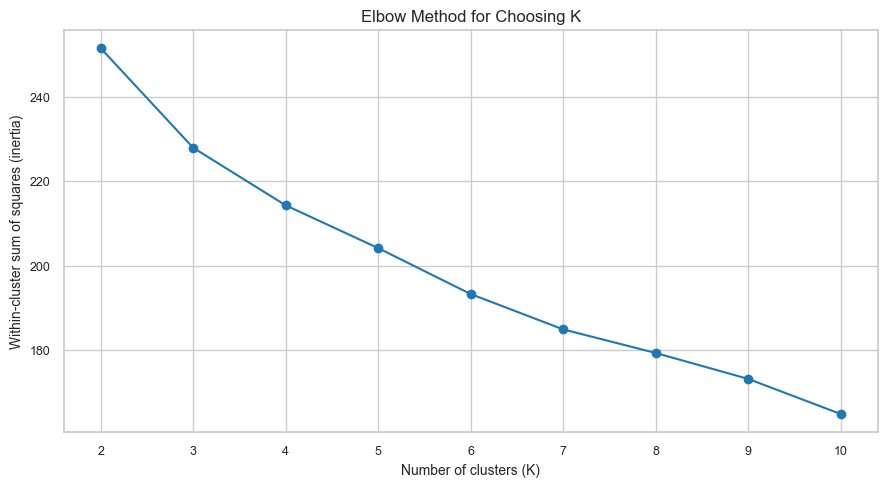

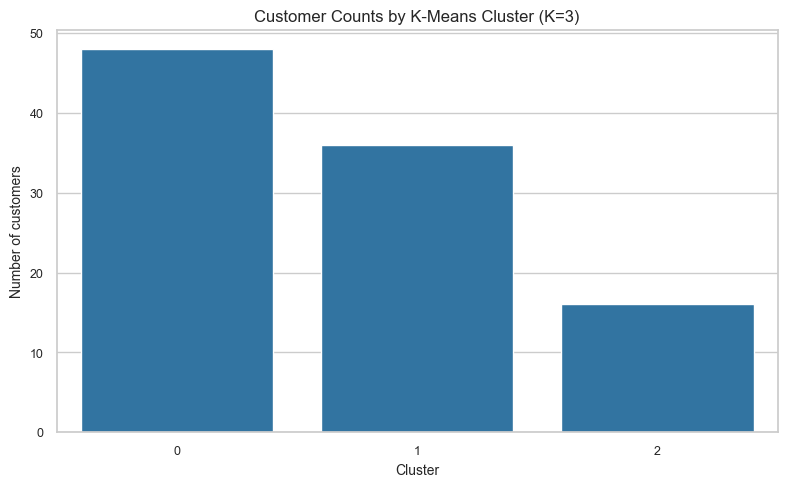

Inertia by K: {2: np.float64(251.46), 3: np.float64(227.9), 4: np.float64(214.29), 5: np.float64(204.18), 6: np.float64(193.31), 7: np.float64(184.95), 8: np.float64(179.37), 9: np.float64(173.24), 10: np.float64(164.95)}
A lower inertia is better in isolation, but larger K always lowers inertia.
Use the elbow (where improvement slows) together with silhouette scores to choose K.
Provisional K for the next steps: 3


In [6]:
import numpy as np
from sklearn.cluster import KMeans

# Select only the 0/1 offer-response columns; exclude customer names, and cluster
offer_columns = [col for col in customer_offer_matrix.columns if col not in ["customer_name", "cluster"]]
x_cols = customer_offer_matrix[offer_columns].to_numpy(dtype=int)
X = x_cols

# Lower within-cluster sum of squares (inertia) means points are closer to their centroids.
# Inertia always decreases as K increases, so use the elbow shape rather than the smallest value alone.
k_values = range(2, 11)
inertias = []
kmeans_models = {}

for k in k_values:
    # Fit a reproducible K-Means model for each candidate number of clusters.
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    model.fit(X)
    inertias.append(model.inertia_)
    kmeans_models[k] = model

# Plot the elbow curve to look for the point where the decrease starts to level off.
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values), fontsize=9)
plt.yticks(fontsize=9)
plt.xlabel("Number of clusters (K)", fontsize=10)
plt.ylabel("Within-cluster sum of squares (inertia)", fontsize=10)
plt.title("Elbow Method for Choosing K", fontsize=12)
plt.tight_layout()
plt.show()

# Choose a provisional K from the elbow plot; the silhouette analysis below provides another check.
# K=3 is a useful starting point for this dataset, but compare it with the plotted metrics.
provisional_k = 3
best_kmeans = kmeans_models[provisional_k]
customer_offer_matrix["cluster"] = best_kmeans.labels_

# Plot the number of customers assigned to each cluster.
cluster_counts = customer_offer_matrix["cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_counts.index.astype(str), y=cluster_counts.values)
plt.xlabel("Cluster", fontsize=10)
plt.ylabel("Number of customers", fontsize=10)
plt.title(
    f"Customer Counts by K-Means Cluster (K={provisional_k})",
    fontsize=12
)
plt.xticks(fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

print("Inertia by K:", dict(zip(k_values, np.round(inertias, 2))))
print("A lower inertia is better in isolation, but larger K always lowers inertia.")
print("Use the elbow (where improvement slows) together with silhouette scores to choose K.")
print("Provisional K for the next steps:", provisional_k)

- **Which SS values are better?** Lower within-cluster sum of squares (SS), also called inertia, indicates that customers are closer to their assigned cluster centroids. However, SS decreases as the number of clusters (K) increases, so the lowest value alone does not identify the best clustering. The elbow method looks for the point where the improvement starts to slow down.
  
- **How challenging is the elbow method?** The main challenge is that the elbow point is not always clear. In this dataset, inertia decreases steadily as K increases, without one unmistakable bend. K = 3 is a reasonable starting point, but other values should also be considered using silhouette scores and the usefulness of the resulting customer segments.

#### 3aii. Choosing K: The Silhouette Method

There exists another method that measures how well each datapoint $x_i$ "fits" its assigned cluster *and also* how poorly it fits into other clusters. This is a different way of looking at the same objective. Denote $a_{x_i}$ as the *average* distance from $x_i$ to all other points within its own cluster $k$. The lower the value, the better. On the other hand $b_{x_i}$ is the minimum average distance from $x_i$ to points in a different cluster, minimized over clusters. That is, compute separately for each cluster the average distance from $x_i$ to the points within that cluster, and then take the minimum. The silhouette $s(x_i)$ is defined as

$$s(x_i) = \frac{b_{x_i} - a_{x_i}}{\max{\left( a_{x_i}, b_{x_i}\right)}}$$

The silhouette score is computed on *every datapoint in every cluster*. The silhouette score ranges from -1 (a poor clustering) to +1 (a very dense clustering) with 0 denoting the situation where clusters overlap. Some criteria for the silhouette coefficient is provided in the table below.

<pre>

| Range       | Interpretation                                |
|-------------|-----------------------------------------------|
| 0.71 - 1.0  | A strong structure has been found.            |
| 0.51 - 0.7  | A reasonable structure has been found.        |
| 0.26 - 0.5  | The structure is weak and could be artificial.|
| < 0.25      | No substantial structure has been found.      |

</pre>
Source: http://www.stat.berkeley.edu/~spector/s133/Clus.html

**Hint**: Scikit-learn provides a function to compute this for us (phew!) called [`sklearn.metrics.silhouette_score`](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html). Take a look at [this article](http://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html) on picking $K$ in scikit-learn, as it will help you in the next exercise set.

<div class="span5 alert alert-info">
<h3>Checkup Exercise Set III</h3>

<p><b>Exercise:</b> Using the documentation for the `silhouette_score` function above, construct a series of silhouette plots like the ones in the article linked above.</p>

<p><b>Exercise:</b> Compute the average silhouette score for each $K$ and plot it. What $K$ does the plot suggest we should choose? Does it differ from what we found using the Elbow method?</p>
</div>

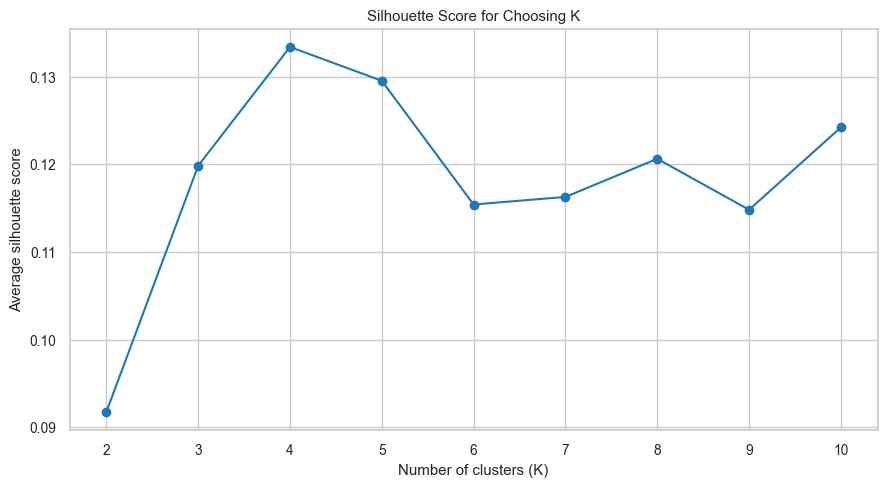

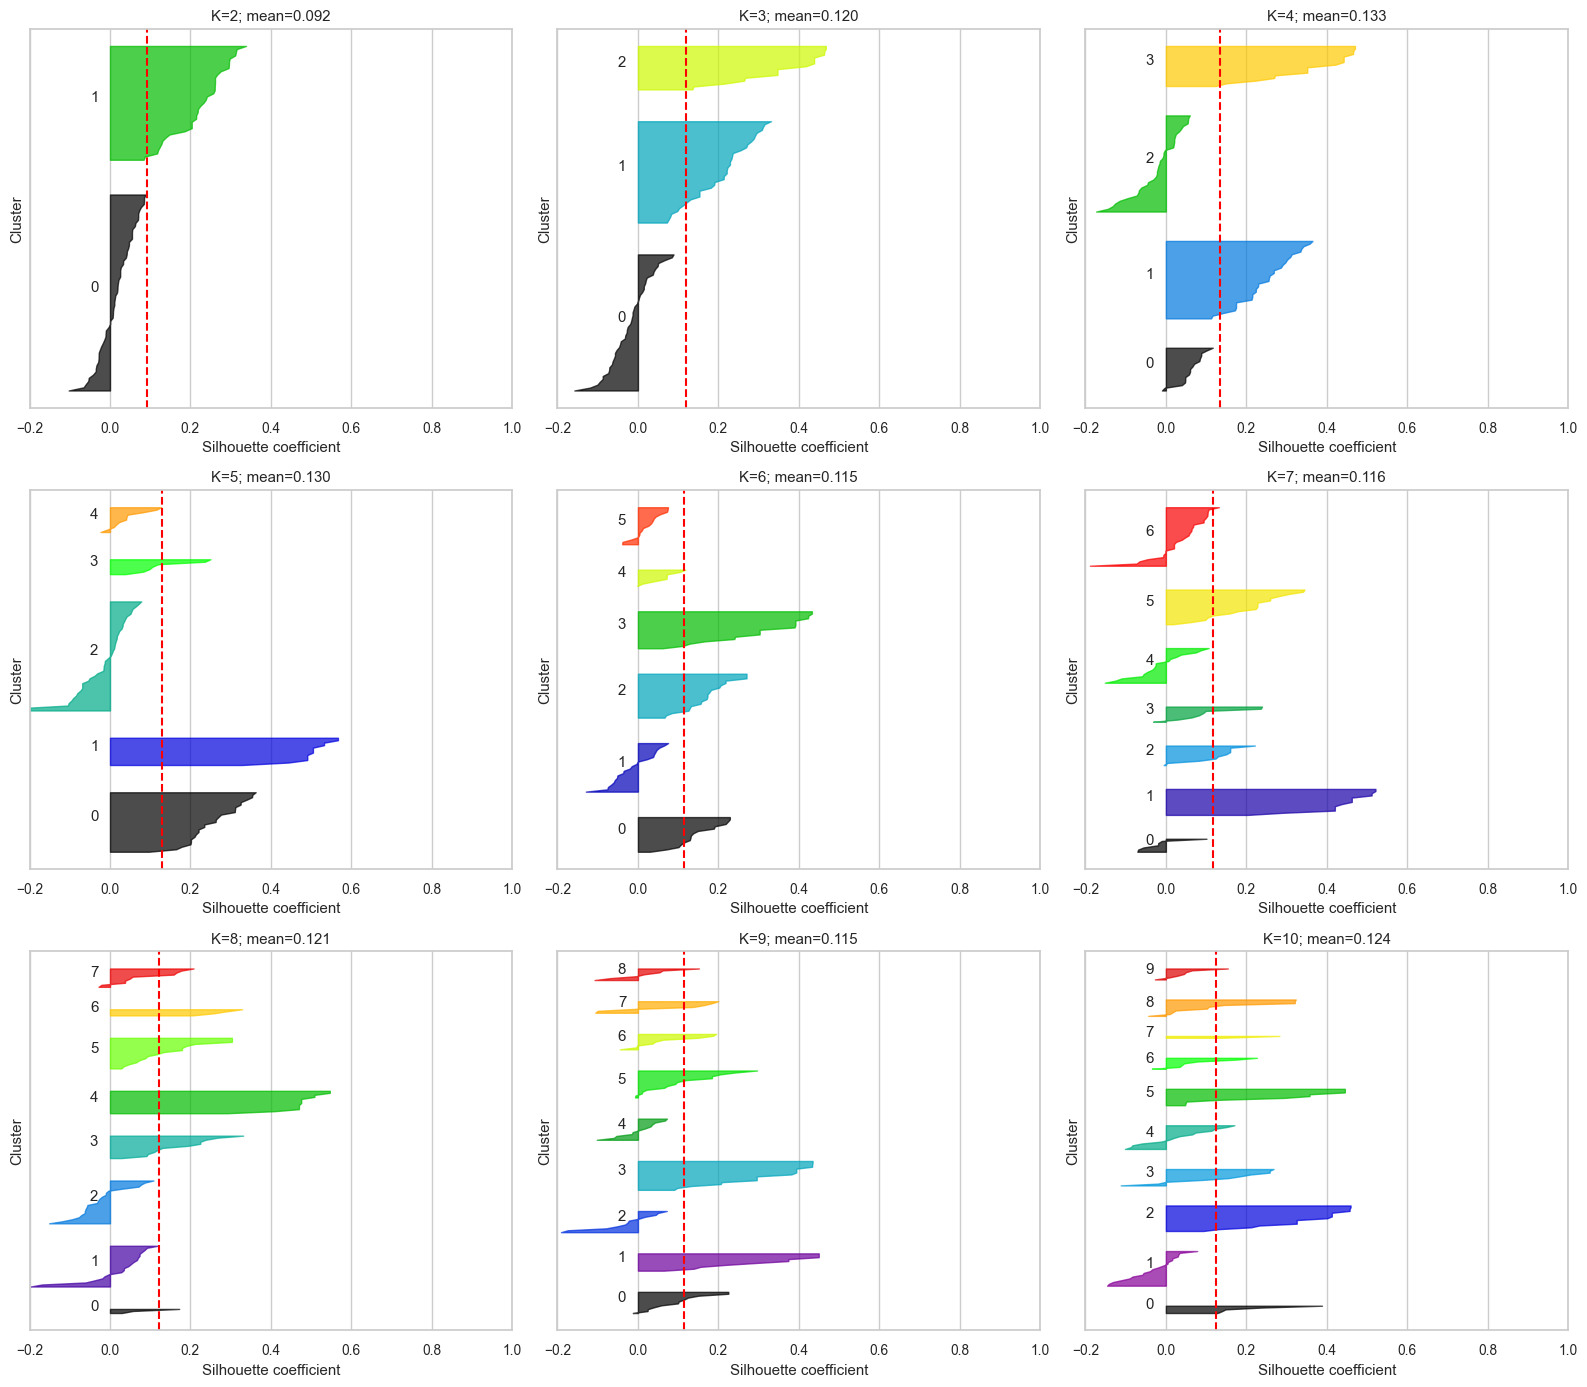

Average silhouette scores: {2: 0.092, 3: 0.12, 4: 0.133, 5: 0.13, 6: 0.115, 7: 0.116, 8: 0.121, 9: 0.115, 10: 0.124}
Highest average silhouette score: K=4 (score=0.133)
Compare this K with the elbow plot: the methods may suggest different values.


In [7]:
from sklearn.metrics import silhouette_score, silhouette_samples
from matplotlib import cm

# Calculate the average silhouette score for each K from 2 through 10.
silhouette_scores = {}
for k in range(2, 11):
    labels = kmeans_models[k].labels_
    silhouette_scores[k] = silhouette_score(X, labels)

# Plot the average silhouette scores to compare cluster separation and cohesion.
plt.figure(figsize=(9, 5))
plt.plot(list(silhouette_scores.keys()), list(silhouette_scores.values()), marker="o")
plt.xticks(list(silhouette_scores.keys()))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Average silhouette score")
plt.title("Silhouette Score for Choosing K")
plt.tight_layout()
plt.show()

# Build silhouette plots for each candidate K, following the scikit-learn example.
# Each horizontal band represents customers in a cluster; wider positive values are better.
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
axes = axes.flatten()

for ax, k in zip(axes, range(2, 11)):
    labels = kmeans_models[k].labels_
    sample_values = silhouette_samples(X, labels)
    y_lower = 10

    for cluster_id in range(k):
        values = np.sort(sample_values[labels == cluster_id])
        size = len(values)
        y_upper = y_lower + size
        color = cm.nipy_spectral(float(cluster_id) / k)
        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7
        )
        ax.text(-0.05, y_lower + 0.5 * size, str(cluster_id))
        y_lower = y_upper + 10

    ax.axvline(silhouette_scores[k], color="red", linestyle="--")
    ax.set_title(f"K={k}; mean={silhouette_scores[k]:.3f}")
    ax.set_xlabel("Silhouette coefficient")
    ax.set_ylabel("Cluster")
    ax.set_yticks([])
    ax.set_xlim(-0.2, 1.0)

plt.tight_layout()
plt.show()

# Identify the K with the highest average silhouette score.
best_silhouette_k = max(silhouette_scores, key=silhouette_scores.get)
print("Average silhouette scores:", {k: round(v, 3) for k, v in silhouette_scores.items()})
print(f"Highest average silhouette score: K={best_silhouette_k} "
      f"(score={silhouette_scores[best_silhouette_k]:.3f})")
print("Compare this K with the elbow plot: the methods may suggest different values.")


- **What does the plot suggest we should choose, and does it differ from what we found using the Elbow method?** The silhouette plot suggests choosing **K = 4**, which has the highest average silhouette score of 0.133. This differs from the Elbow method, which suggested **K = 3** as a reasonable choice. However, the silhouette score is low, indicating that the clusters are not well separated. Therefore, K = 4 performs best according to the silhouette score, while K = 3 remains a reasonable option based on the Elbow method.

#### 3aiii.  Choosing $K$: The Gap Statistic

There is one last method worth covering for picking $K$, the so-called Gap statistic. The computation for the gap statistic builds on the sum-of-squares established in the Elbow method discussion, and compares it to the sum-of-squares of a "null distribution," that is, a random set of points with no clustering. The estimate for the optimal number of clusters $K$ is the value for which $\log{SS}$ falls the farthest below that of the reference distribution:

$$G_k = E_n^*\{\log SS_k\} - \log SS_k$$

In other words a good clustering yields a much larger difference between the reference distribution and the clustered data. The reference distribution is a Monte Carlo (randomization) procedure that constructs $B$ random distributions of points within the bounding box (limits) of the original data and then applies K-means to this synthetic distribution of data points.. $E_n^*\{\log SS_k\}$ is just the average $SS_k$ over all $B$ replicates. We then compute the standard deviation $\sigma_{SS}$ of the values of $SS_k$ computed from the $B$ replicates of the reference distribution and compute

$$s_k = \sqrt{1+1/B}\sigma_{SS}$$

Finally, we choose $K=k$ such that $G_k \geq G_{k+1} - s_{k+1}$.

#### Aside: Choosing $K$ when we Have Labels

Unsupervised learning expects that we do not have the labels. In some situations, we may wish to cluster data that is labeled. Computing the optimal number of clusters is much easier if we have access to labels. There are several methods available. We will not go into the math or details since it is rare to have access to the labels, but we provide the names and references of these measures.

* Adjusted Rand Index
* Mutual Information
* V-Measure
* Fowlkes–Mallows index

**Hint:** See [this article](http://scikit-learn.org/stable/modules/clustering.html) for more information about these metrics.

### 3b. Visualizing Clusters using PCA

How do we visualize clusters? If we only had two features, we could likely plot the data as is. But we have 100 data points each containing 32 features (dimensions). Principal Component Analysis (PCA) will help us reduce the dimensionality of our data from 32 to something lower. For a visualization on the coordinate plane, we will use 2 dimensions. In this exercise, we're going to use it to transform our multi-dimensional dataset into a 2 dimensional dataset.

This is only one use of PCA for dimension reduction. We can also use PCA when we want to perform regression but we have a set of highly correlated variables. PCA untangles these correlations into a smaller number of features/predictors all of which are orthogonal (not correlated). PCA is also used to reduce a large set of variables into a much smaller one.

**Hint:** PCA was discussed in the previous subunit. If you need help with it, consult [this useful article](https://towardsdatascience.com/a-one-stop-shop-for-principal-component-analysis-5582fb7e0a9c) and [this visual explanation](http://setosa.io/ev/principal-component-analysis/). 

<div class="span5 alert alert-info">
<h3>Checkup Exercise Set IV</h3>

<p><b>Exercise:</b> Use PCA to plot your clusters:</p>

<ul>
<li> Use scikit-learn's [`PCA`](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) function to reduce the dimensionality of your clustering data to 2 components
<li> Create a data frame with the following fields:
  <ul>
  <li> customer name
  <li> cluster id the customer belongs to
  <li> the two PCA components (label them `x` and `y`)
  </ul>
<li> Plot a scatterplot of the `x` vs `y` columns
<li> Color-code points differently based on cluster ID
<li> How do the clusters look? 
<li> Based on what you see, what seems to be the best value for $K$? Moreover, which method of choosing $K$ seems to have produced the optimal result visually?
</ul>

<p><b>Exercise:</b> Now look at both the original raw data about the offers and transactions and look at the fitted clusters. Tell a story about the clusters in context of the original data. For example, do the clusters correspond to wine variants or something else interesting?</p>
</div>

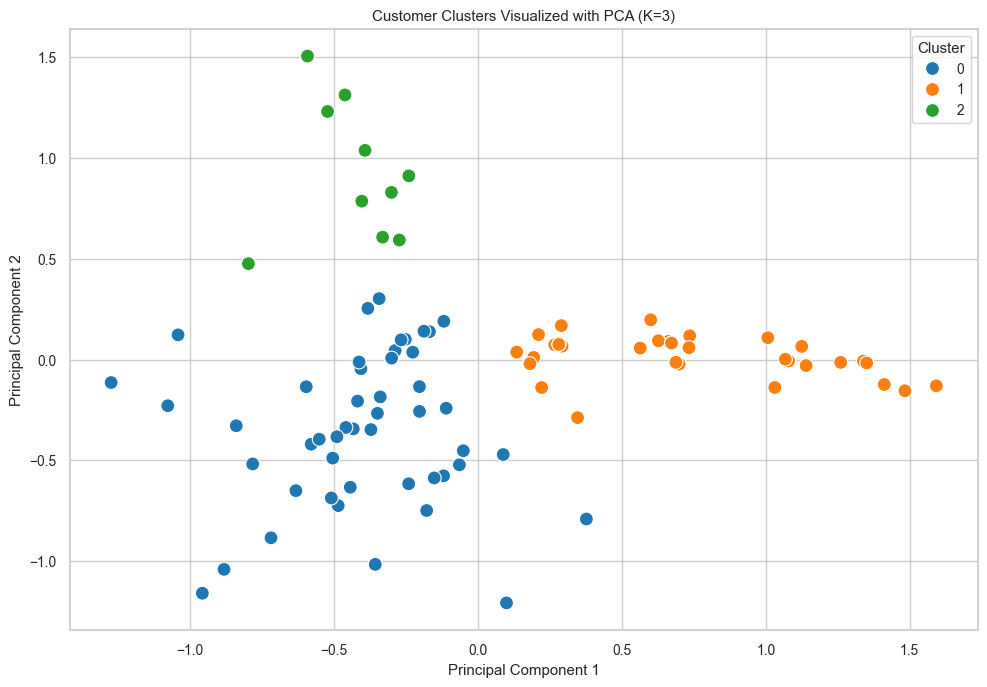

Explained variance by the first two components: [0.144 0.108]
Combined variance explained: 0.252


,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,27,28,29,30,31,32
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.19,0.08,0.10,0.25,0.08,0.23,0.08,0.08,0.19,0.08,...,0.08,0.00,0.10,0.06,0.15,0.10,0.02,0.08,0.35,0.08
1,0.00,0.00,0.03,0.00,0.00,0.03,0.42,0.44,0.03,0.06,...,0.00,0.00,0.03,0.00,0.03,0.03,0.44,0.50,0.00,0.00
2,0.06,0.38,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.06,...,0.06,0.75,0.00,0.75,0.06,0.00,0.00,0.00,0.00,0.00



Cluster 0: most frequently accepted offers


,campaign,varietal,min_qty,discount,origin,past_peak,acceptance_rate
offer_id,,,,,,,
22,August,Champagne,72,63,France,False,0.437500
31,December,Champagne,72,89,France,False,0.354167
11,May,Champagne,72,85,France,False,0.250000
4,February,Champagne,72,48,France,True,0.250000
6,March,Prosecco,144,86,Chile,False,0.229167



Cluster 1: most frequently accepted offers


,campaign,varietal,min_qty,discount,origin,past_peak,acceptance_rate
offer_id,,,,,,,
30,December,Malbec,6,54,France,False,0.500000
29,November,Pinot Grigio,6,87,France,False,0.444444
8,March,Espumante,6,45,South Africa,False,0.444444
7,March,Prosecco,6,40,Australia,True,0.416667
18,July,Espumante,6,50,Oregon,False,0.361111



Cluster 2: most frequently accepted offers


,campaign,varietal,min_qty,discount,origin,past_peak,acceptance_rate
offer_id,,,,,,,
26,October,Pinot Noir,144,83,Australia,False,0.7500
24,September,Pinot Noir,6,34,Italy,False,0.7500
17,July,Pinot Noir,12,47,Germany,False,0.4375
2,January,Pinot Noir,72,17,France,False,0.3750
10,April,Prosecco,72,52,California,False,0.0625


Interpretation: clusters group customers by similarity in the offers they accepted.
Offer summaries help identify differences in wine variety, campaign, discount,
quantity, origin, and other offer characteristics.
Overlap in two PCA dimensions does not necessarily mean the full-dimensional
clusters are identical.


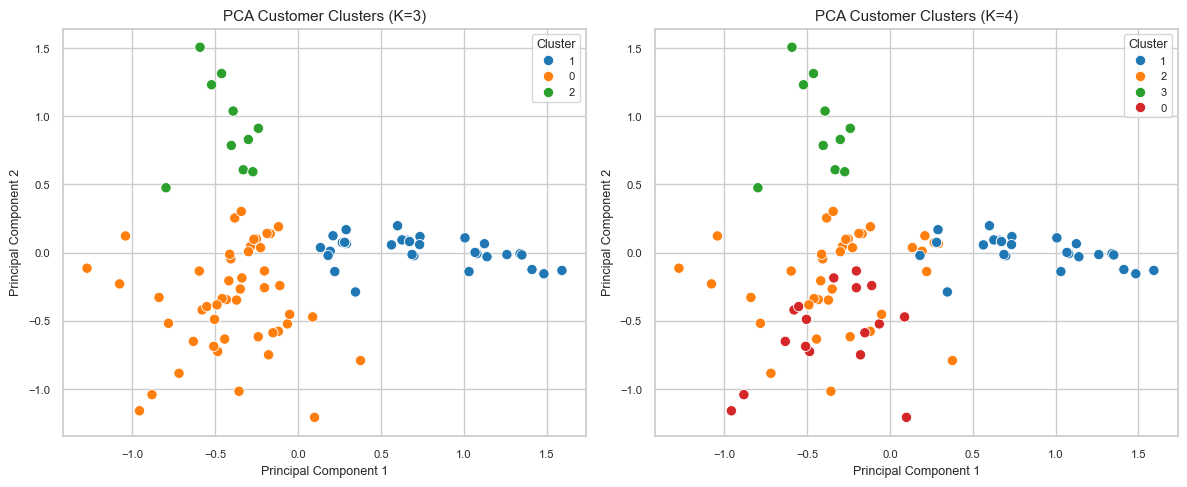

In [8]:

#your turn

from sklearn.decomposition import PCA

# Select the offer-response features.
X = customer_offer_matrix[offer_columns].values

# Use PCA to reduce the data to two dimensions.
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X)

# Create a data frame with customer names, cluster IDs, and PCA coordinates.
pca_df = pd.DataFrame({
    "customer_name": customer_offer_matrix["customer_name"],
    "cluster": best_kmeans.labels_,
    "x": X_pca[:, 0],
    "y": X_pca[:, 1]
})

# Plot the provisional K-Means clusters.
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df,
    x="x",
    y="y",
    hue="cluster",
    palette="tab10",
    s=100
)
plt.title(f"Customer Clusters Visualized with PCA (K={provisional_k})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Explained variance by the first two components:",
    np.round(pca_2d.explained_variance_ratio_, 3)
)
print(
    "Combined variance explained:",
    round(pca_2d.explained_variance_ratio_.sum(), 3)
)

# Summarize offer acceptance rates for each cluster.
cluster_offer_rates = customer_offer_matrix.groupby("cluster")[offer_columns].mean()
display(cluster_offer_rates.round(2))

# Show the five most frequently accepted offers for each cluster.
offer_details = df_offers.set_index("offer_id")

for cluster_id, rates in cluster_offer_rates.iterrows():
    top_offer_ids = rates.sort_values(ascending=False).head(5).index

    print(f"\nCluster {cluster_id}: most frequently accepted offers")

    display(
        offer_details.loc[
            [int(offer_id) for offer_id in top_offer_ids],
            ["campaign", "varietal", "min_qty", "discount", "origin", "past_peak"]
        ]
        .assign(acceptance_rate=rates.loc[top_offer_ids].values)
        .sort_values("acceptance_rate", ascending=False)
    )

print("Interpretation: clusters group customers by similarity in the offers they accepted.")
print("Offer summaries help identify differences in wine variety, campaign, discount,")
print("quantity, origin, and other offer characteristics.")
print("Overlap in two PCA dimensions does not necessarily mean the full-dimensional")
print("clusters are identical.")

# Compare the Elbow choice (K=3) and Silhouette choice (K=4).
# Use the same PCA coordinates for both plots.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, k in zip(axes, [3, 4]):
    labels = kmeans_models[k].labels_

    plot_df = pd.DataFrame({
        "x": X_pca[:, 0],
        "y": X_pca[:, 1],
        "cluster": labels.astype(str)
    })

    sns.scatterplot(
        data=plot_df,
        x="x",
        y="y",
        hue="cluster",
        palette="tab10",
        s=55,
        ax=ax
    )

    ax.set_title(f"PCA Customer Clusters (K={k})", fontsize=11)
    ax.set_xlabel("Principal Component 1", fontsize=9)
    ax.set_ylabel("Principal Component 2", fontsize=9)
    ax.tick_params(axis="both", labelsize=8)
    ax.legend(title="Cluster", fontsize=8, title_fontsize=9)

plt.tight_layout()
plt.show()


- **How do the clusters look?** The PCA scatterplot displays the customer clusters in two dimensions. Some overlap may occur because PCA reduces the original 32 offer-response features to only two principal components. The first two components explain 25.2% of the total variance, so the plot provides only a partial view of the differences between clusters.
- **Which K looks best visually?** The Elbow method suggests K = 3, while the Silhouette method suggests K = 4. The silhouette score is highest at K = 4 (0.133), but the score is low, indicating limited separation between clusters. Comparing PCA scatterplots for both values of K can help assess their visual separation, although the two-dimensional projection alone cannot determine the best clustering.
- **What do the clusters mean?** The clusters show different patterns of customer responses to wine offers. Cluster 0 has relatively high acceptance rates for several Champagne offers, including offer 22 (43.8%). Cluster 1 responds relatively often to offers with a minimum quantity of 6 bottles, such as offer 30 (50.0%) and offer 29 (44.4%). Cluster 2 has high acceptance rates for selected Pinot Noir offers, including offers 24 and 26 (both 75.0%). These patterns suggest that customers differ in the offers they accept, although the clusters reflect combinations of offer-response behaviors rather than a single customer characteristic.

What we've done is we've taken those columns of 0/1 indicator variables, and we've transformed them into a 2-D dataset. We took one column and arbitrarily called it `x` and then called the other `y`. Now we can throw each point into a scatterplot. We color coded each point based on it's cluster so it's easier to see them.

<div class="span5 alert alert-info">
<h3>Exercise Set V</h3>

<p>As we saw earlier, PCA has a lot of other uses. Since we wanted to visualize our data in 2 dimensions, restricted the number of dimensions to 2 in PCA. But what is the true optimal number of dimensions?</p>

<p><b>Exercise:</b> Using a new PCA object shown in the next cell, plot the `explained_variance_` field and look for the elbow point, the point where the curve's rate of descent seems to slow sharply. This value is one possible value for the optimal number of dimensions. What is it?</p>
</div>

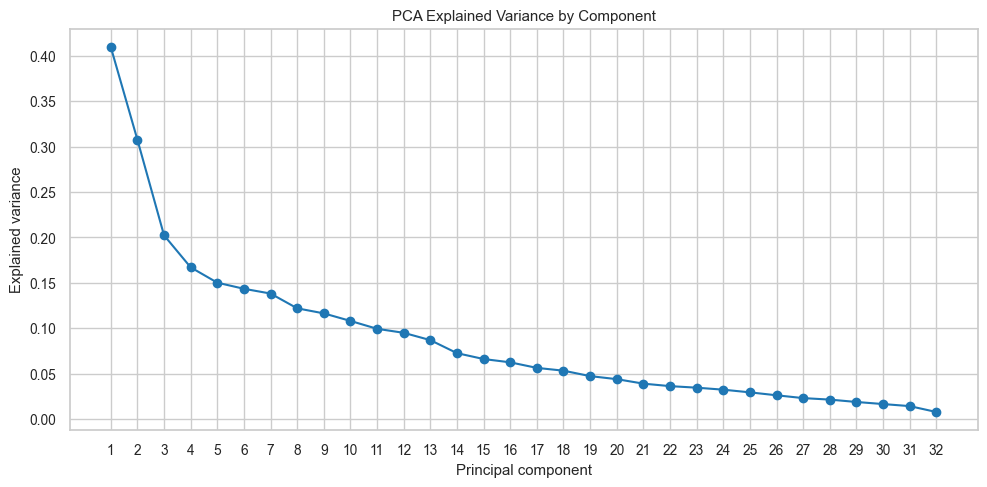

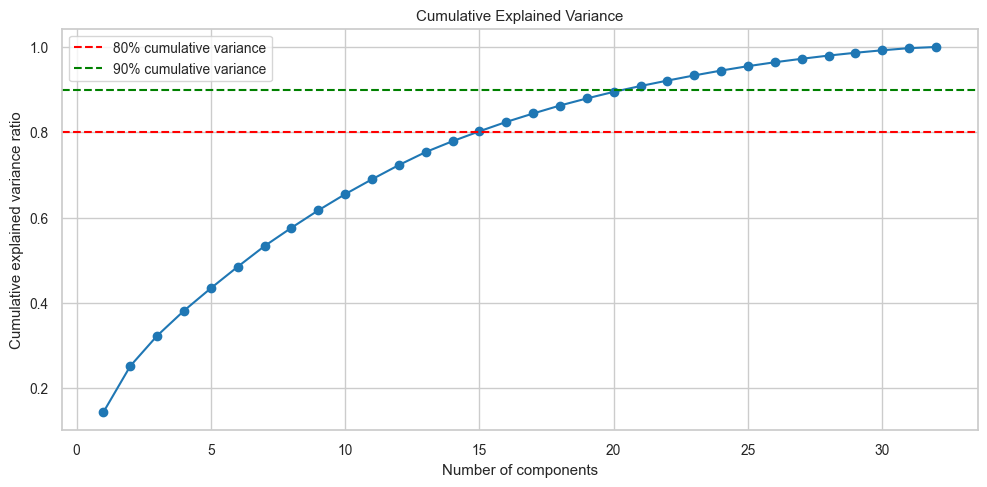

Explained variance ratios: [0.144 0.108 0.071 0.059 0.053 0.05  0.049 0.043 0.041 0.038 0.035 0.033
 0.031 0.025 0.023 0.022 0.02  0.019 0.017 0.015 0.014 0.013 0.012 0.011
 0.01  0.009 0.008 0.008 0.007 0.006 0.005 0.003]
Cumulative explained variance: [0.144 0.252 0.323 0.382 0.434 0.485 0.533 0.576 0.617 0.655 0.69  0.723
 0.754 0.779 0.802 0.824 0.844 0.863 0.879 0.895 0.908 0.921 0.933 0.945
 0.955 0.964 0.972 0.98  0.986 0.992 0.997 1.   ]
Choose the elbow where the explained-variance curve starts to flatten;
confirm it against the cumulative variance plot rather than assuming one exact answer.


In [9]:
# Initialize a new PCA model with a default number of components.
import sklearn.decomposition
pca = sklearn.decomposition.PCA()
pca.fit(X)

# Plot explained variance by principal component to look for an elbow.
# The curve helps estimate how many components capture most of the variation.
component_numbers = np.arange(1, len(pca.explained_variance_) + 1)

plt.figure(figsize=(10, 5))
plt.plot(component_numbers, pca.explained_variance_, marker="o")
plt.xlabel("Principal component")
plt.ylabel("Explained variance")
plt.title("PCA Explained Variance by Component")
plt.xticks(component_numbers)
plt.tight_layout()
plt.show()

# Also show cumulative explained variance to support the visual elbow choice.
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(10, 5))
plt.plot(component_numbers, cumulative_variance, marker="o")
plt.axhline(0.80, color="red", linestyle="--", label="80% cumulative variance")
plt.axhline(0.90, color="green", linestyle="--", label="90% cumulative variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance ratio")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

print("Explained variance ratios:", np.round(pca.explained_variance_ratio_, 3))
print("Cumulative explained variance:", np.round(cumulative_variance, 3))
print("Choose the elbow where the explained-variance curve starts to flatten;")
print("confirm it against the cumulative variance plot rather than assuming one exact answer.")

The explained-variance curve drops more sharply across the first few principal components and then begins to flatten. The elbow appears to be around the third or fourth component, although the bend is not very pronounced. The cumulative explained variance provides additional context: 4 components explain 38.2% of the variance, while 15 components explain approximately 80.2%. Therefore, the elbow provides a possible low-dimensional representation, but more components are needed to retain most of the information in the original dataset.

## 4. Conclusions and next steps
### 4a. Conclusions
What can you conclude from your investigations? Make a note, formulate it as clearly as possible, and be prepared to discuss it with your mentor in your next call. 

### Conclusions

The customer-offer matrix was successfully created from the transaction data, containing 100 customers and 32 binary offer-response features with no missing values.

The elbow method suggested K = 3 as a reasonable starting point, while the silhouette method selected K = 4, with an average silhouette score of 0.133. The low silhouette score indicates that the customer groups are not strongly separated, so the clustering results should be interpreted with caution.

The PCA visualization reduced the 32 offer-response features to two dimensions, explaining 25.2% of the total variance. The offer summaries also revealed differences in customer responses: one cluster showed relatively high acceptance of several Champagne offers, another responded frequently to offers with low minimum quantities, and a third showed high acceptance of selected Pinot Noir offers.

Overall, K-Means provides a useful starting point for exploring customer offer-response patterns, but the results do not establish clearly separated customer segments. Comparing different values of K, examining alternative clustering algorithms, and validating whether the segments support useful marketing decisions would help improve the analysis.

### 4b. Other clustering algorithms

k-means is only one of a ton of clustering algorithms. Below is a brief description of several clustering algorithms, and the table provides references to the other clustering algorithms in scikit-learn. 

* **Affinity Propagation** does not require the number of clusters $K$ to be known in advance! AP uses a "message passing" paradigm to cluster points based on their similarity. 

* **Spectral Clustering** uses the eigenvalues of a similarity matrix to reduce the dimensionality of the data before clustering in a lower dimensional space. This is tangentially similar to what we did to visualize k-means clusters using PCA. The number of clusters must be known a priori.

* **Ward's Method** applies to hierarchical clustering. Hierarchical clustering algorithms take a set of data and successively divide the observations into more and more clusters at each layer of the hierarchy. Ward's method is used to determine when two clusters in the hierarchy should be combined into one. It is basically an extension of hierarchical clustering. Hierarchical clustering is *divisive*, that is, all observations are part of the same cluster at first, and at each successive iteration, the clusters are made smaller and smaller. With hierarchical clustering, a hierarchy is constructed, and there is not really the concept of "number of clusters." The number of clusters simply determines how low or how high in the hierarchy we reference and can be determined empirically or by looking at the [dendogram](https://docs.scipy.org/doc/scipy-0.18.1/reference/generated/scipy.cluster.hierarchy.dendrogram.html).

* **Agglomerative Clustering** is similar to hierarchical clustering but but is not divisive, it is *agglomerative*. That is, every observation is placed into its own cluster and at each iteration or level or the hierarchy, observations are merged into fewer and fewer clusters until convergence. Similar to hierarchical clustering, the constructed hierarchy contains all possible numbers of clusters and it is up to the analyst to pick the number by reviewing statistics or the dendogram.

* **DBSCAN** is based on point density rather than distance. It groups together points with many nearby neighbors. DBSCAN is one of the most cited algorithms in the literature. It does not require knowing the number of clusters a priori, but does require specifying the neighborhood size.

### Clustering Algorithms in Scikit-learn
<table border="1">
<colgroup>
<col width="15%" />
<col width="16%" />
<col width="20%" />
<col width="27%" />
<col width="22%" />
</colgroup>
<thead valign="bottom">
<tr><th>Method name</th>
<th>Parameters</th>
<th>Scalability</th>
<th>Use Case</th>
<th>Geometry (metric used)</th>
</tr>
</thead>
<tbody valign="top">
<tr><td>K-Means</span></a></td>
<td>number of clusters</td>
<td>Very large<span class="pre">n_samples</span>, medium <span class="pre">n_clusters</span> with
MiniBatch code</td>
<td>General-purpose, even cluster size, flat geometry, not too many clusters</td>
<td>Distances between points</td>
</tr>
<tr><td>Affinity propagation</td>
<td>damping, sample preference</td>
<td>Not scalable with n_samples</td>
<td>Many clusters, uneven cluster size, non-flat geometry</td>
<td>Graph distance (e.g. nearest-neighbor graph)</td>
</tr>
<tr><td>Mean-shift</td>
<td>bandwidth</td>
<td>Not scalable with <span class="pre">n_samples</span></td>
<td>Many clusters, uneven cluster size, non-flat geometry</td>
<td>Distances between points</td>
</tr>
<tr><td>Spectral clustering</td>
<td>number of clusters</td>
<td>Medium <span class="pre">n_samples</span>, small <span class="pre">n_clusters</span></td>
<td>Few clusters, even cluster size, non-flat geometry</td>
<td>Graph distance (e.g. nearest-neighbor graph)</td>
</tr>
<tr><td>Ward hierarchical clustering</td>
<td>number of clusters</td>
<td>Large <span class="pre">n_samples</span> and <span class="pre">n_clusters</span></td>
<td>Many clusters, possibly connectivity constraints</td>
<td>Distances between points</td>
</tr>
<tr><td>Agglomerative clustering</td>
<td>number of clusters, linkage type, distance</td>
<td>Large <span class="pre">n_samples</span> and <span class="pre">n_clusters</span></td>
<td>Many clusters, possibly connectivity constraints, non Euclidean
distances</td>
<td>Any pairwise distance</td>
</tr>
<tr><td>DBSCAN</td>
<td>neighborhood size</td>
<td>Very large <span class="pre">n_samples</span>, medium <span class="pre">n_clusters</span></td>
<td>Non-flat geometry, uneven cluster sizes</td>
<td>Distances between nearest points</td>
</tr>
<tr><td>Gaussian mixtures</td>
<td>many</td>
<td>Not scalable</td>
<td>Flat geometry, good for density estimation</td>
<td>Mahalanobis distances to  centers</td>
</tr>
<tr><td>Birch</td>
<td>branching factor, threshold, optional global clusterer.</td>
<td>Large <span class="pre">n_clusters</span> and <span class="pre">n_samples</span></td>
<td>Large dataset, outlier removal, data reduction.</td>
<td>Euclidean distance between points</td>
</tr>
</tbody>
</table>
Source: http://scikit-learn.org/stable/modules/clustering.html

<div class="span5 alert alert-info">
<h3>Exercise Set VI</h3>

<p><b>Exercise:</b> Try clustering using the following algorithms. </p>
<ol>
<li>Affinity propagation
<li>Spectral clustering
<li>Agglomerative clustering
<li>DBSCAN
</ol>
<p>How do their results compare? Which performs the best? Tell a story why you think it performs the best.</p>
</div>


,Algorithm,Clusters (excluding noise),Noise points,Silhouette score
2,Agglomerative Clustering,3,0,0.116
1,Spectral Clustering,3,0,0.115
0,Affinity Propagation,11,0,0.112
3,DBSCAN,1,3,NaN


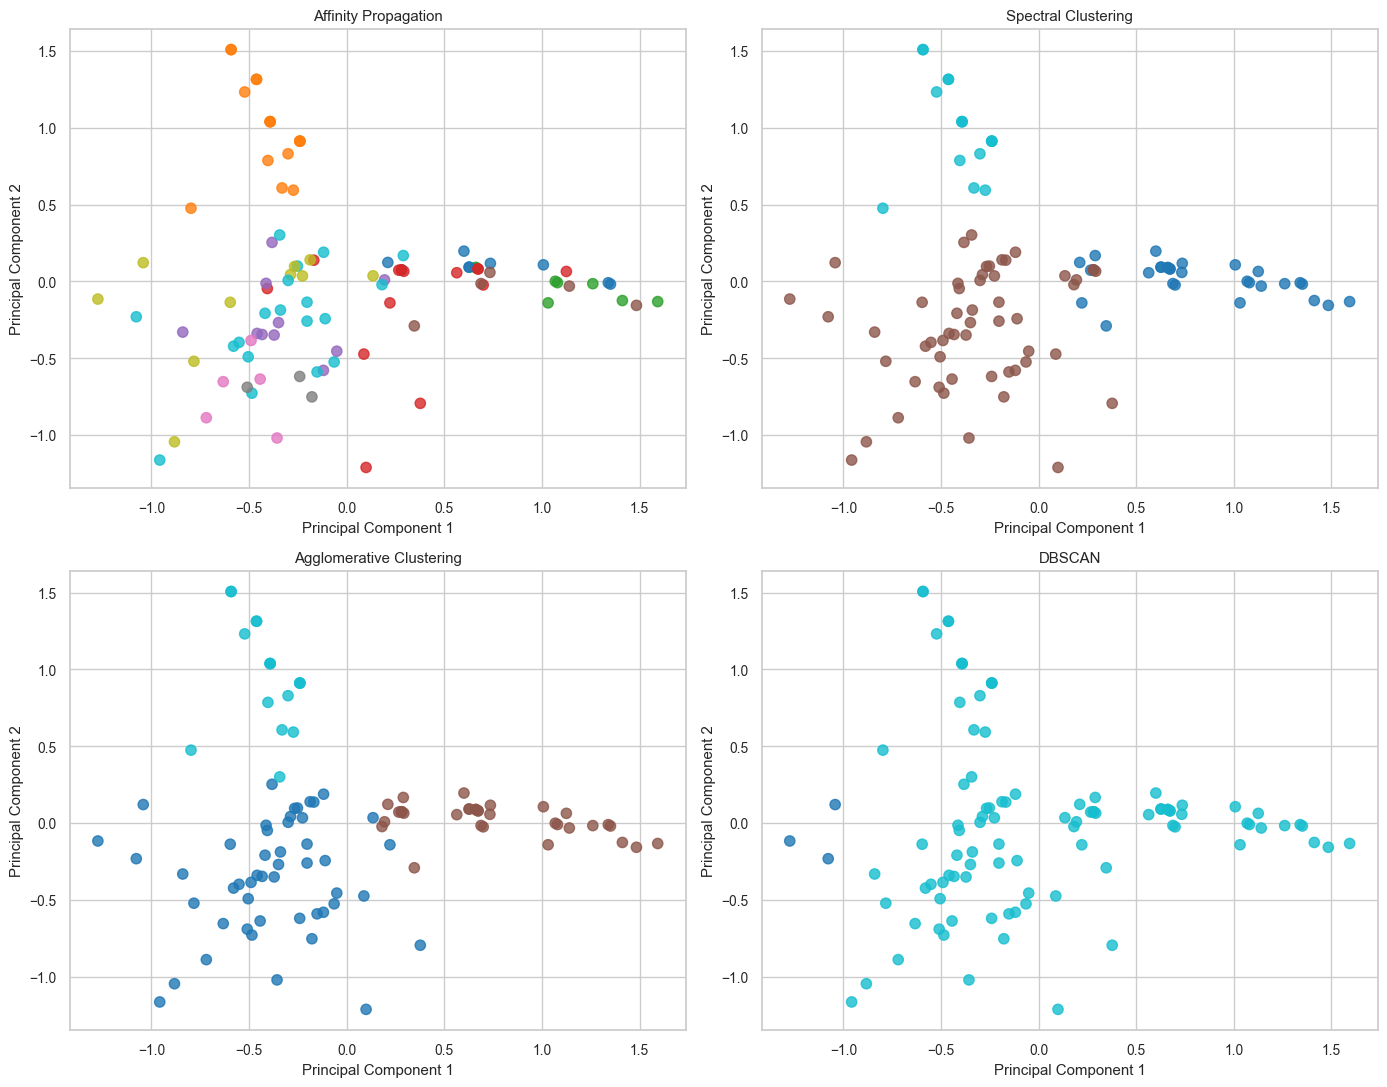

Comparison guidance:
- Prefer a method with a reasonable silhouette score, interpretable groups, and useful cluster sizes.
- Affinity Propagation does not require K in advance but may form too many or uneven clusters.
- Spectral clustering can capture non-flat structure but depends on the similarity graph.
- Agglomerative clustering is useful for hierarchical groupings and a specified number of clusters.
- DBSCAN can detect dense groups and noise, but may label most customers as noise if eps is unsuitable.
There is no universally best algorithm; choose based on metric results and whether the groups
show meaningful differences in the accepted wine offers.


In [10]:
# Your turn

from sklearn.cluster import AffinityPropagation, SpectralClustering, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
import warnings

# Use the same binary customer-offer features to compare clustering algorithms fairly.
# K-Means suggested K=3 as a useful baseline; spectral and agglomerative clustering use the same K.
algorithm_labels = {}

# Affinity Propagation estimates the number of clusters from the data.
# It can be sensitive to preference and may produce many small clusters.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    affinity_model = AffinityPropagation(random_state=42, damping=0.9)
    algorithm_labels["Affinity Propagation"] = affinity_model.fit_predict(X)

# Spectral clustering groups observations using a similarity graph.
spectral_model = SpectralClustering(
    n_clusters=provisional_k,
    affinity="nearest_neighbors",
    n_neighbors=10,
    assign_labels="kmeans",
    random_state=42
)
algorithm_labels["Spectral Clustering"] = spectral_model.fit_predict(X)

# Agglomerative clustering builds a hierarchy and cuts it into the requested number of clusters.
agglomerative_model = AgglomerativeClustering(n_clusters=provisional_k, linkage="ward")
algorithm_labels["Agglomerative Clustering"] = agglomerative_model.fit_predict(X)

# DBSCAN finds dense regions and marks observations outside dense regions as noise (-1).
# Its result depends on eps and min_samples; these values are starting points, not universal defaults.
dbscan_model = DBSCAN(eps=2.0, min_samples=4, metric="euclidean")
algorithm_labels["DBSCAN"] = dbscan_model.fit_predict(X)

# Compare the number of clusters, noise points, and silhouette score where it is meaningful.
comparison_rows = []
for algorithm_name, labels in algorithm_labels.items():
    unique_labels = set(labels)
    n_clusters = len(unique_labels - {-1})
    n_noise = int(np.sum(labels == -1))

    # Silhouette score requires at least two clusters and fewer clusters than observations.
    # For DBSCAN, exclude noise points from the score when enough non-noise clusters remain.
    score = np.nan
    valid_mask = labels != -1
    valid_labels = labels[valid_mask]
    if len(set(valid_labels)) >= 2 and len(set(valid_labels)) < len(valid_labels):
        score = silhouette_score(X[valid_mask], valid_labels)

    comparison_rows.append({
        "Algorithm": algorithm_name,
        "Clusters (excluding noise)": n_clusters,
        "Noise points": n_noise,
        "Silhouette score": score
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    "Silhouette score", ascending=False, na_position="last"
)
display(comparison_df.round(3))

# Visualize each algorithm's assignments using the same two PCA components.
pca_for_comparison = PCA(n_components=2, random_state=42)
X_pca_comparison = pca_for_comparison.fit_transform(X)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (algorithm_name, labels) in zip(axes.flatten(), algorithm_labels.items()):
    scatter = ax.scatter(
        X_pca_comparison[:, 0],
        X_pca_comparison[:, 1],
        c=labels,
        cmap="tab10",
        s=55,
        alpha=0.8
    )
    ax.set_title(algorithm_name)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

print("Comparison guidance:")
print("- Prefer a method with a reasonable silhouette score, interpretable groups, and useful cluster sizes.")
print("- Affinity Propagation does not require K in advance but may form too many or uneven clusters.")
print("- Spectral clustering can capture non-flat structure but depends on the similarity graph.")
print("- Agglomerative clustering is useful for hierarchical groupings and a specified number of clusters.")
print("- DBSCAN can detect dense groups and noise, but may label most customers as noise if eps is unsuitable.")
print("There is no universally best algorithm; choose based on metric results and whether the groups")
print("show meaningful differences in the accepted wine offers.")

- **How do their results compare?** Agglomerative clustering produced the highest silhouette score among the four tested alternative algorithms, at 0.116, followed closely by Spectral Clustering at 0.115. Affinity Propagation produced 11 clusters and a slightly lower score of 0.112. DBSCAN identified one non-noise cluster and three noise points, so a valid silhouette score could not be calculated for its non-noise observations.

- **Which performs the best?** Based on the silhouette scores, Agglomerative Clustering performed best among these four alternatives. However, its score is low and is only slightly higher than the score for Spectral Clustering, so the difference is small. The results do not show strong cluster separation. DBSCAN was less useful with the current parameter settings because it did not identify at least two non-noise clusters. Overall, Agglomerative Clustering is the best-performing alternative by the reported silhouette metric, but further parameter testing and evaluation of the business usefulness of the segments are needed before selecting a final model.